# Project: Investigate a Dataset - No-Show Appointments

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#eda">Exploratory Data Analysis</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>

<a id='intro'></a>
## Introduction

### Dataset Description

This project analyses the **No-Show Appointments** dataset (source: Kaggle / Brazilian Ministry of Health), which records **110,527 medical appointments** scheduled in Vitória, Brazil, between 2015 and 2016. Each row describes a single appointment and whether the patient attended.

| Column | Type | Description |
|---|---|---|
| PatientId | int | Unique patient identifier |
| AppointmentID | int | Unique appointment identifier |
| Gender | str | Patient gender: M or F |
| ScheduledDay | str | ISO-8601 timestamp when appointment was booked |
| AppointmentDay | str | ISO-8601 timestamp of the appointment itself |
| Age | int | Patient age in years |
| Neighbourhood | str | Hospital neighbourhood |
| Scholarship | int | 1 if enrolled in Bolsa Família welfare programme |
| Hipertension | int | 1 if patient has hypertension |
| Diabetes | int | 1 if patient has diabetes |
| Alcoholism | int | 1 if patient has alcoholism |
| Handcap | int | Handicap severity 0–4 |
| SMS_received | int | 1 if patient received an SMS reminder |
| No-show | str | **'Yes'** = did NOT attend; **'No'** = DID attend ⚠️ counterintuitive |

> ⚠️ **Encoding note**: The `No-show` column is counterintuitively labelled. `'Yes'` means the patient *missed* the appointment; `'No'` means they *attended*. We correct this during wrangling.

### Research Questions

1. **RQ1 - Patient Demographics & Health**: Which patient characteristics (age group, gender, social-welfare enrolment, and chronic-condition status) are associated with higher no-show rates?
2. **RQ2 - Waiting Time**: How does the number of days between scheduling and the appointment date affect the probability of a no-show?
3. **RQ3 - SMS Reminders**: Does receiving an SMS reminder reduce the no-show rate, and does its effectiveness vary with waiting time?

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
%matplotlib inline

# Consistent plot aesthetics across all figures
plt.rcParams.update({
    'figure.figsize': (10, 5),
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
})

<a id='wrangling'></a>
## Data Wrangling

### General Properties

We begin with six inspection calls to understand shape, types, missing values, duplicates, and value distributions before touching a single row.

In [39]:
# Load the dataset (CSV is in the same directory as this notebook)
df = pd.read_csv('Database_No_show_appointments\\noshowappointments-kagglev2-may-2016.csv')

print(f"Shape: {df.shape[0]:,} rows  x  {df.shape[1]} columns")
df.head()

Shape: 110,527 rows  x  14 columns


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [40]:
# Column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 17.6 MB


In [41]:
# Descriptive statistics for numeric columns
df.describe()

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [42]:
# Missing values per column
print("=== Missing Values ===")
print(df.isnull().sum())

# Duplicate rows
print(f"\n=== Duplicate Rows: {df.duplicated().sum()} ===")

# Value counts for the target column (counterintuitive encoding)
print("\n=== No-show Value Counts ===")
print(df['No-show'].value_counts())
print("  Note: 'No' = patient attended; 'Yes' = patient did NOT attend")

=== Missing Values ===
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

=== Duplicate Rows: 0 ===

=== No-show Value Counts ===
No-show
No     88208
Yes    22319
Name: count, dtype: int64
  Note: 'No' = patient attended; 'Yes' = patient did NOT attend


In [43]:
# Spot-check age distribution for errant values
print("Age range:", df['Age'].min(), "to", df['Age'].max())
print("Rows with Age < 0:", (df['Age'] < 0).sum())

Age range: -1 to 115
Rows with Age < 0: 1


### Data Cleaning

Based on the inspection above, the following cleaning steps are applied:

1. **Rename columns** to snake_case for ergonomics.
2. **Convert date columns** (`ScheduledDay`, `AppointmentDay`) from raw strings to `datetime` objects.
3. **Re-encode the target**: Create a binary `no_show` column (1 = missed, 0 = attended) from the counterintuitive original.
4. **Engineer `wait_days`**: Days elapsed between scheduling and the appointment.
5. **Remove errant rows**: Drop the single row with `age == -1` and any rows where `wait_days < 0` (appointment logged before it was scheduled - likely data-entry errors).
6. **Drop identifiers**: `PatientId` and `AppointmentID` carry no analytical signal.
7. **Engineer categorical bins**: `age_group` (four life-stage bands) and `wait_category` (four scheduling-lag bands) for grouped analysis.

In [44]:
# ── Step 1: Standardise column names ────────────────────────────────────────
df.columns = [
    'patient_id', 'appointment_id', 'gender', 'scheduled_day',
    'appointment_day', 'age', 'neighbourhood', 'scholarship',
    'hypertension', 'diabetes', 'alcoholism', 'handicap',
    'sms_received', 'no_show'
]

# ── Step 2: Parse date columns ───────────────────────────────────────────────
df['scheduled_day']   = pd.to_datetime(df['scheduled_day'],   utc=True)
df['appointment_day'] = pd.to_datetime(df['appointment_day'], utc=True)

# ── Step 3: Re-encode target variable ────────────────────────────────────────
# Original encoding: 'Yes' = did NOT show up  |  'No' = DID show up
df['no_show'] = (df['no_show'] == 'Yes').astype(int)

# ── Step 4: Derive wait_days (corrected) ────────────────────────────────────
# Strip the time component from both columns before subtracting so that
# same-day appointments are correctly recorded as 0 days, not -1.
df['wait_days'] = (
    df['appointment_day'].dt.normalize() -
    df['scheduled_day'].dt.normalize()
).dt.days

# ── Step 5: Remove errant rows ───────────────────────────────────────────────
n_before = len(df)
df = df[(df['age'] >= 0) & (df['wait_days'] >= 0)].copy()
print(f"Removed {n_before - len(df)} errant row(s)  "
      f"(age < 0 or wait_days < 0)")

# ── Step 6: Drop identifier columns ─────────────────────────────────────────
df.drop(['patient_id', 'appointment_id'], axis=1, inplace=True)

print(f"Cleaned dataset: {df.shape[0]:,} rows  x  {df.shape[1]} columns")
df.head()

Removed 6 errant row(s)  (age < 0 or wait_days < 0)
Cleaned dataset: 110,521 rows  x  13 columns


,gender,scheduled_day,appointment_day,age,neighbourhood,scholarship,hypertension,diabetes,alcoholism,handicap,sms_received,no_show,wait_days
0,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,0,0
1,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,0,0
2,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,0,0
3,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,0,0
4,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,0,0


In [45]:
# ── Step 7: Categorical bins for grouped analysis ───────────────────────────

# Four life-stage age bands
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 17, 39, 59, 115],
    labels=['0-17', '18-39', '40-59', '60+'],
    include_lowest=True
)

# Four scheduling-lag bands
df['wait_category'] = pd.cut(
    df['wait_days'],
    bins=[-1, 0, 7, 30, 365],
    labels=['Same Day', '1-7 Days', '8-30 Days', '31+ Days']
)

# ── Baseline: overall no-show rate ──────────────────────────────────────────
total        = len(df)
total_noshows = df['no_show'].sum()
overall_rate  = df['no_show'].mean() * 100
print(f"Total appointments : {total:,}")
print(f"Total no-shows     : {total_noshows:,}")
print(f"Overall no-show rate: {overall_rate:.2f}%")

Total appointments : 110,521
Total no-shows     : 22,314
Overall no-show rate: 20.19%


<a id='eda'></a>
## Exploratory Data Analysis

For each research question we perform:
- **1-D analysis** - distribution of individual variables in isolation.
- **2-D analysis** - relationship between the variable and the no-show rate.

Two reusable helper functions (`plot_noshow_rate` and `describe_group`) are defined once and called repeatedly to ensure consistent chart formatting and statistical summaries across all questions.

In [46]:
def plot_noshow_rate(data, column, title, xlabel,
                    figsize=(10, 5), colors=None):
    """
    Compute and plot the no-show rate (%) for each category in `column`.
    Adds a horizontal reference line for the overall rate.
    Returns a Series of rates (index = category label, values = %).
    Called for every categorical variable explored across RQ1, RQ2, RQ3.
    """
    rates    = data.groupby(column, observed=True)['no_show'].mean() * 100
    n_cats   = len(rates)
    palette  = colors if colors else plt.cm.tab10.colors[:n_cats]

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(rates.index.astype(str), rates.values,
                  color=palette, edgecolor='black', width=0.6)

    # Value labels above each bar
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2.,
                bar.get_height() + 0.4,
                f'{bar.get_height():.1f}%',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

    # Overall no-show rate reference line
    overall = data['no_show'].mean() * 100
    ax.axhline(overall, color='red', linestyle='--', linewidth=1.4,
               label=f'Overall rate ({overall:.1f}%)')

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('No-Show Rate (%)')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.legend(fontsize=10)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    return rates


def describe_group(data, column):
    """
    Print a concise statistical summary (total, no-shows, rate %) for
    each category of `column`.  Called alongside plot_noshow_rate for
    every variable explored to pair every chart with numeric evidence.
    """
    summary = data.groupby(column, observed=True).agg(
        total        = ('no_show', 'count'),
        no_shows     = ('no_show', 'sum'),
        no_show_rate = ('no_show', lambda x: round(x.mean() * 100, 2))
    )
    summary['no_show_rate'] = summary['no_show_rate'].map('{:.2f}%'.format)
    print(summary.to_string())
    return summary

### Research Question 1 - Which Patient Characteristics Are Associated with Higher No-Show Rates?

**Dependent variable:** `no_show` (binary)
**Independent variables explored:** age (distribution), age group, gender, scholarship status, chronic conditions (hypertension, diabetes)

We start with 1-D distributions, then move to 2-D comparisons against the no-show rate.

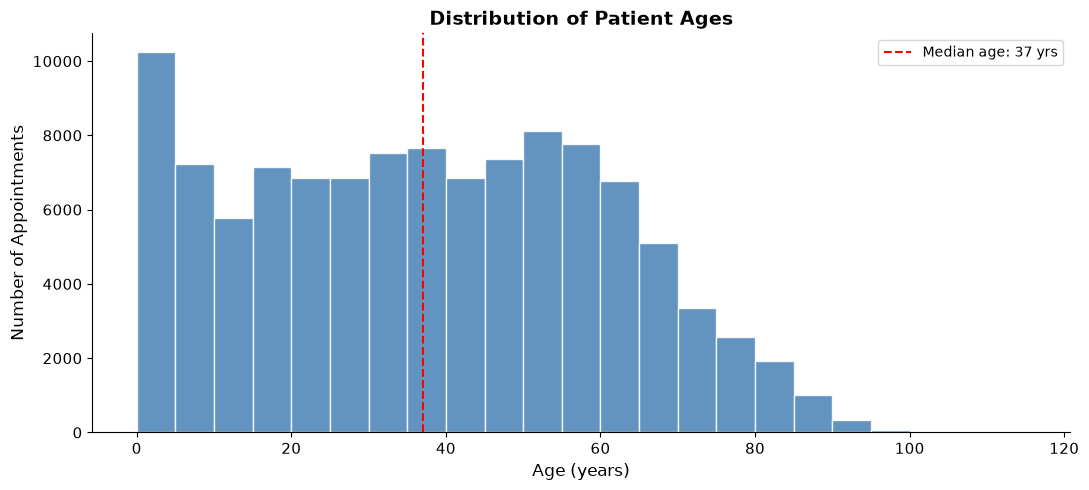

count    110521.0
mean         37.1
std          23.1
min           0.0
25%          18.0
50%          37.0
75%          55.0
max         115.0
Name: age, dtype: float64


In [47]:
# ── 1-D: Distribution of patient age ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(df['age'], bins=range(0, 120, 5),
        color='steelblue', edgecolor='white', alpha=0.85)
median_age = df['age'].median()
ax.axvline(median_age, color='red', linestyle='--', linewidth=1.5,
           label=f'Median age: {median_age:.0f} yrs')
ax.set_title('Distribution of Patient Ages')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Number of Appointments')
ax.legend()
plt.tight_layout()
plt.show()

print(df['age'].describe().round(1))

No-Show Rate by Gender
-----------------------------------
        total  no_shows no_show_rate
gender                              
F       71836     14591       20.31%
M       38685      7723       19.96%



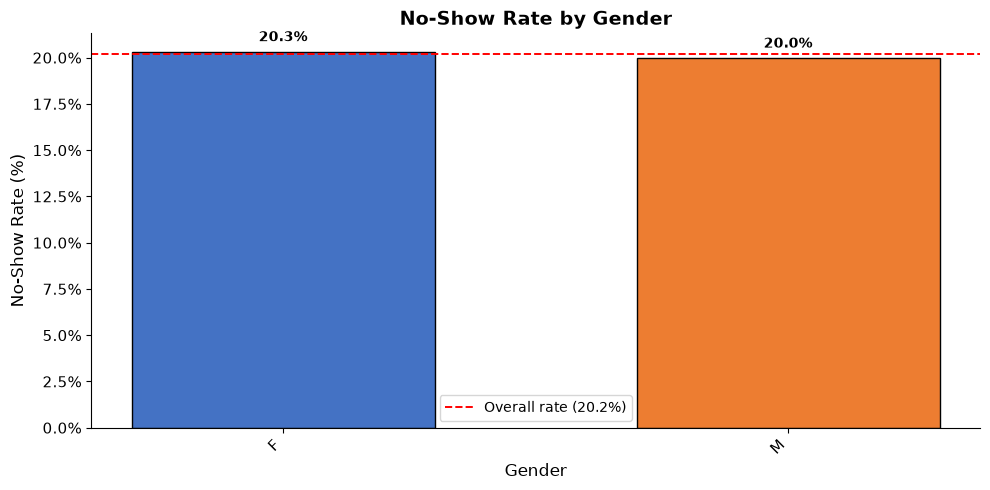

gender
F    20.311543
M    19.963810
Name: no_show, dtype: float64

In [48]:
# ── 2-D: No-show rate by gender ─────────────────────────────────────────────
print("No-Show Rate by Gender")
print("-" * 35)
describe_group(df, 'gender')
print()
plot_noshow_rate(df, 'gender',
                 'No-Show Rate by Gender',
                 'Gender',
                 colors=['#4472C4', '#ED7D31'])

No-Show Rate by Age Group
-----------------------------------
           total  no_shows no_show_rate
age_group                              
0-17       27378      5996       21.90%
18-39      31899      7421       23.26%
40-59      30072      5656       18.81%
60+        21172      3241       15.31%



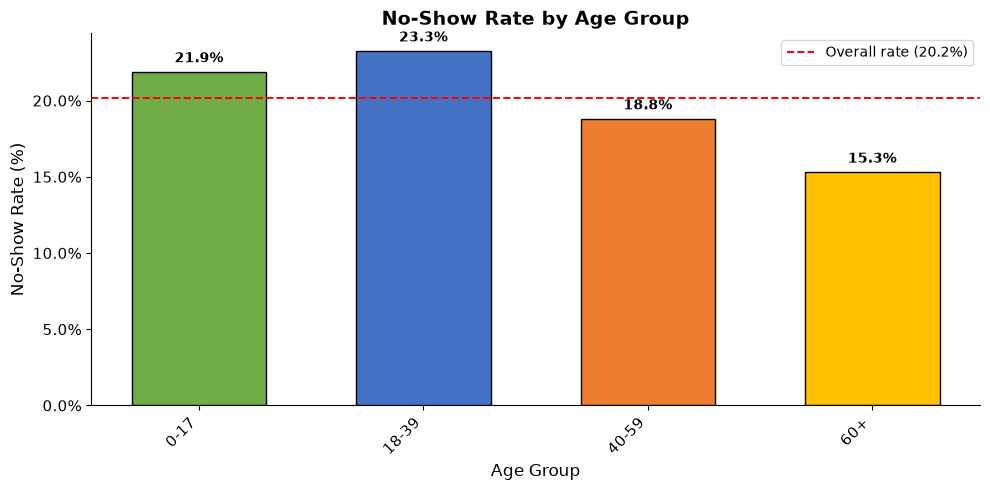

age_group
0-17     21.900796
18-39    23.264052
40-59    18.808194
60+      15.307954
Name: no_show, dtype: float64

In [49]:
# ── 2-D: No-show rate by age group ──────────────────────────────────────────
print("No-Show Rate by Age Group")
print("-" * 35)
describe_group(df, 'age_group')
print()
plot_noshow_rate(df, 'age_group',
                 'No-Show Rate by Age Group',
                 'Age Group',
                 colors=['#70AD47', '#4472C4', '#ED7D31', '#FFC000'])

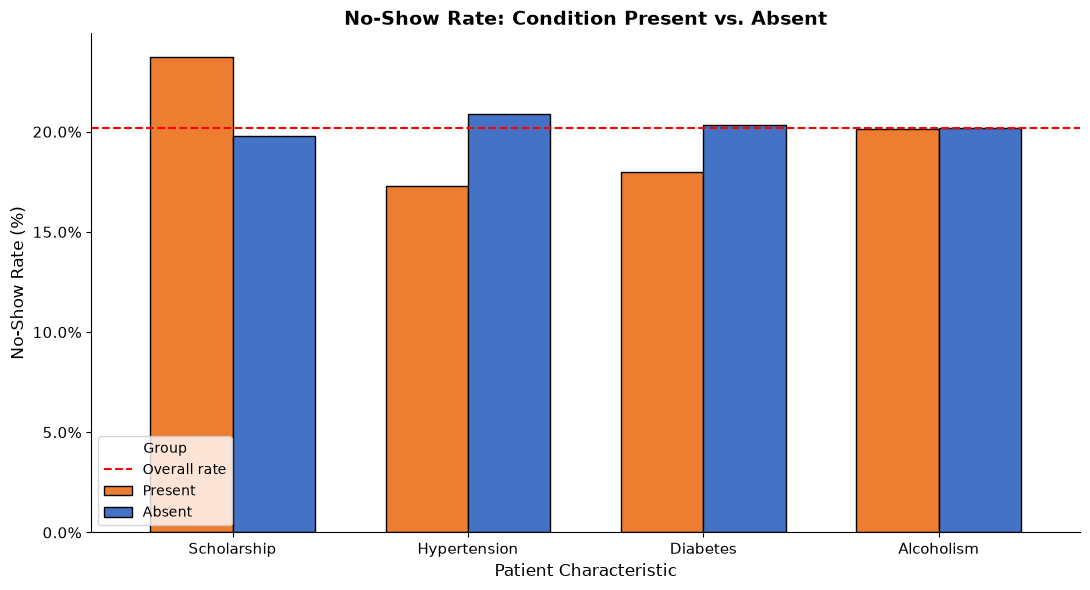

              Present  Absent
Scholarship     23.74   19.80
Hypertension    17.30   20.90
Diabetes        18.00   20.36
Alcoholism      20.15   20.19


In [50]:
# ── 2-D: No-show rate by scholarship and chronic-condition status ─────────────
# Compare rate when condition is present (1) vs. absent (0)
condition_cols = {
    'Scholarship'  : 'scholarship',
    'Hypertension' : 'hypertension',
    'Diabetes'     : 'diabetes',
    'Alcoholism'   : 'alcoholism',
}

rates_present = {label: df[df[col] == 1]['no_show'].mean() * 100
                 for label, col in condition_cols.items()}
rates_absent  = {label: df[df[col] == 0]['no_show'].mean() * 100
                 for label, col in condition_cols.items()}

cond_df = pd.DataFrame({'Present': rates_present, 'Absent': rates_absent})

fig, ax = plt.subplots(figsize=(11, 6))
cond_df.plot(kind='bar', ax=ax,
             color=['#ED7D31', '#4472C4'], edgecolor='black', width=0.7)
ax.axhline(df['no_show'].mean() * 100, color='red', linestyle='--',
           label='Overall rate')
ax.set_title('No-Show Rate: Condition Present vs. Absent')
ax.set_xlabel('Patient Characteristic')
ax.set_ylabel('No-Show Rate (%)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(title='Group', fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(cond_df.round(2))

**Observations - RQ1:**

Gender alone isn’t a strong predictor - no-shows are similar across genders (all around 20%). Younger adults (20s–40s) miss appointments most frequently (~23%), likely due to flexible schedules or competing priorities. Older adults and children (<18) skip visits less often, while those aged 60+ attend more reliably. Participants in Bolsa Família face higher no-show rates (~24% vs. 20%) compared to others, possibly because of transportation hurdles, rigid work schedules, or caregiving demands for younger members. Patients with chronic conditions (e.g., diabetes, hypertension) miss fewer appointments (~17%), suggesting they prioritize them. Alcoholism correlates with slightly higher no-shows, but the reason is unclear.

### Research Question 2 - How Does Waiting Time Affect the No-Show Rate?

We examine the `wait_days` variable (engineered during wrangling as `appointment_day - scheduled_day`) first as a continuous distribution (1-D), then aggregated into four scheduling-lag bands (2-D).

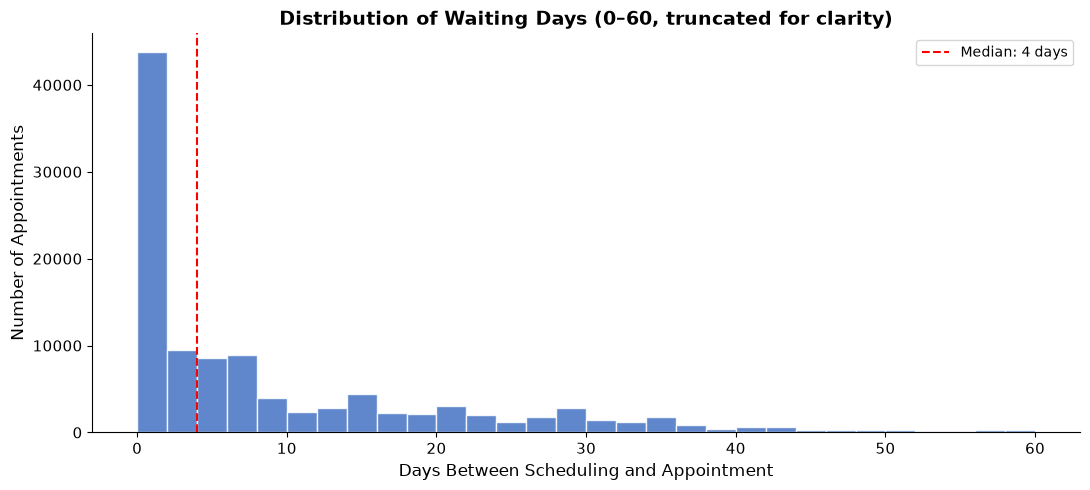

count    110521.0
mean         10.2
std          15.3
min           0.0
25%           0.0
50%           4.0
75%          15.0
max         179.0
Name: wait_days, dtype: float64

Proportion with same-day appointments (0 days): 34.9%


In [51]:
# ── 1-D: Distribution of waiting days (capped at 60 for readability) ─────────
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(df[df['wait_days'] <= 60]['wait_days'],
        bins=30, color='#4472C4', edgecolor='white', alpha=0.85)
median_wait = df['wait_days'].median()
ax.axvline(median_wait, color='red', linestyle='--', linewidth=1.5,
           label=f'Median: {median_wait:.0f} days')
ax.set_title('Distribution of Waiting Days (0–60, truncated for clarity)')
ax.set_xlabel('Days Between Scheduling and Appointment')
ax.set_ylabel('Number of Appointments')
ax.legend()
plt.tight_layout()
plt.show()

print(df['wait_days'].describe().round(1))
print(f"\nProportion with same-day appointments (0 days): "
      f"{(df['wait_days'] == 0).mean()*100:.1f}%")

No-Show Rate by Waiting Time Category
----------------------------------------
               total  no_shows no_show_rate
wait_category                              
Same Day       38562      1792        4.65%
1-7 Days       32185      7772       24.15%
8-30 Days      29396      9325       31.72%
31+ Days       10378      3425       33.00%



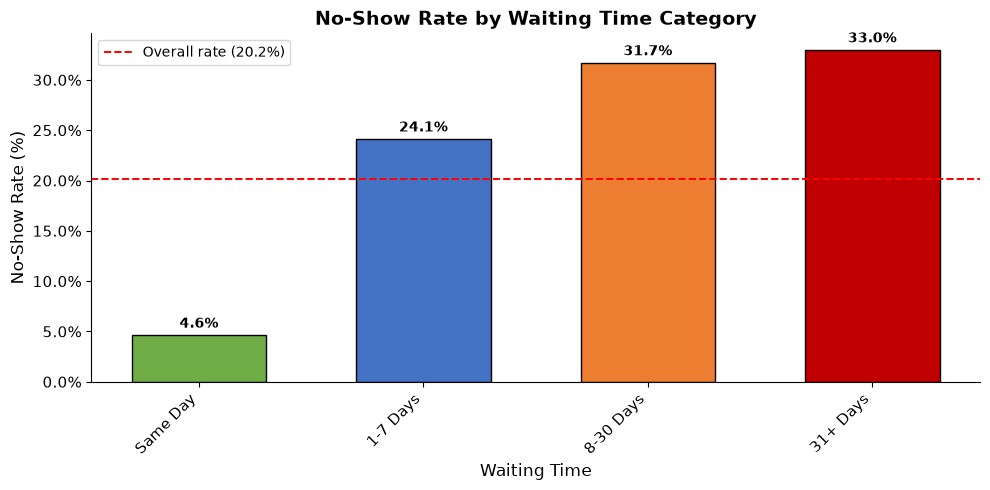

wait_category
Same Day      4.647062
1-7 Days     24.147895
8-30 Days    31.722003
31+ Days     33.002505
Name: no_show, dtype: float64

In [52]:
# ── 2-D: No-show rate by waiting-time category ───────────────────────────────
print("No-Show Rate by Waiting Time Category")
print("-" * 40)
describe_group(df, 'wait_category')
print()
plot_noshow_rate(df, 'wait_category',
                 'No-Show Rate by Waiting Time Category',
                 'Waiting Time',
                 colors=['#70AD47', '#4472C4', '#ED7D31', '#C00000'])

**Observations - RQ2:**

Waiting time is the strongest predictor of no-shows when considering all variables. Appointments scheduled and kept for the same day almost always result in attendance, with under 5% no-shows. No-shows increase sharply as wait times grow: ~24% for 1–7 day waits, ~32% for 8–30 day waits, and over 33% for delays longer than a month. Most appointments cluster at shorter wait periods (primarily within two weeks), but there’s a long tail of extended waits (>30 days) where no-shows peak - though correlation does not confirm causation.

### Research Question 3 - Does Receiving an SMS Reminder Reduce the No-Show Rate?

We examine the no-show rate by `sms_received` (2-D), and then add a second dimension - `wait_category` - to test whether the apparent SMS effect is confounded by scheduling lag.

No-Show Rate by SMS Reminder
-----------------------------------
              total  no_shows no_show_rate
sms_received                              
0             75039     12530       16.70%
1             35482      9784       27.57%



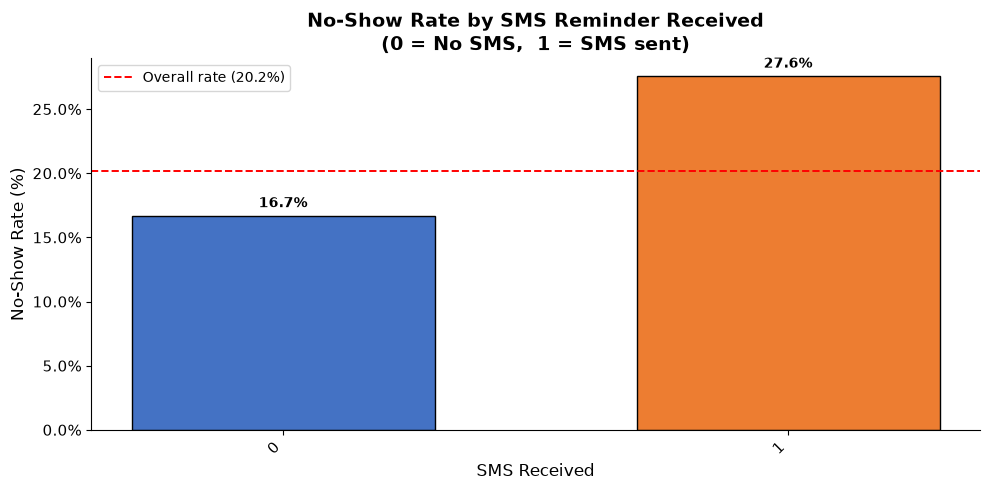

sms_received
0    16.697984
1    27.574545
Name: no_show, dtype: float64

In [53]:
# ── 2-D: No-show rate by SMS reminder status ─────────────────────────────────
print("No-Show Rate by SMS Reminder")
print("-" * 35)
describe_group(df, 'sms_received')
print()
plot_noshow_rate(df, 'sms_received',
                 'No-Show Rate by SMS Reminder Received\n(0 = No SMS,  1 = SMS sent)',
                 'SMS Received',
                 colors=['#4472C4', '#ED7D31'])

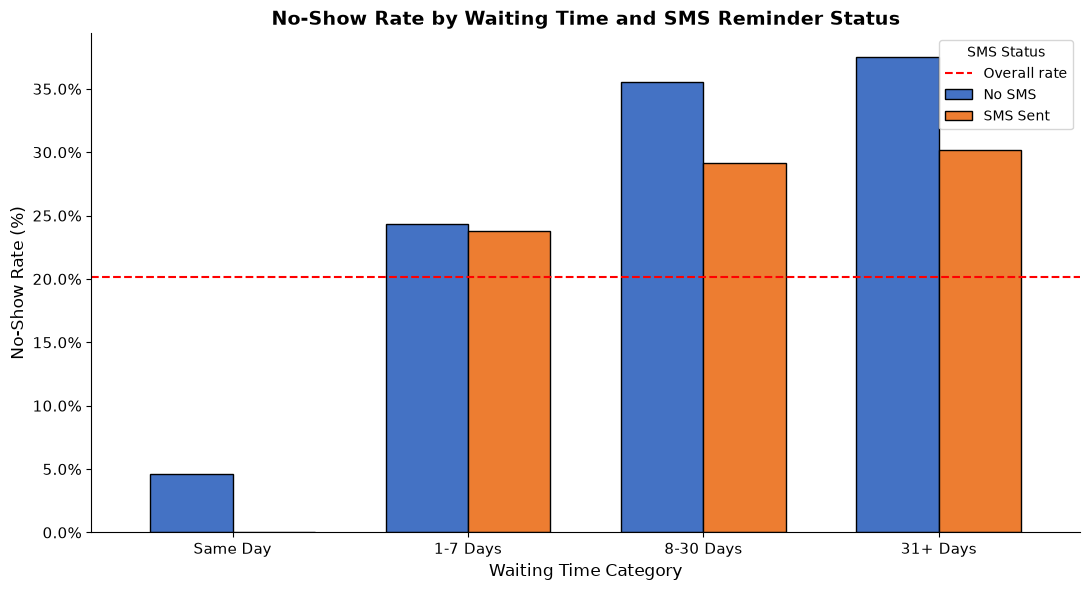

               No SMS  SMS Sent
wait_category                  
Same Day         4.65       NaN
1-7 Days        24.36     23.76
8-30 Days       35.55     29.13
31+ Days        37.53     30.20

--- SMS Coverage by Wait Category ---
wait_category
Same Day      0.0
1-7 Days     35.9
8-30 Days    59.6
31+ Days     61.8


In [54]:
# ── 2-D: Interaction - SMS reminder  x  waiting-time category ────────────────
# Does SMS effectiveness vary depending on how long the patient has waited?
sms_wait = (df.groupby(['wait_category', 'sms_received'], observed=True)['no_show']
              .mean()
              .mul(100)
              .unstack('sms_received'))
sms_wait.columns = ['No SMS', 'SMS Sent']

fig, ax = plt.subplots(figsize=(11, 6))
sms_wait.plot(kind='bar', ax=ax,
              color=['#4472C4', '#ED7D31'], edgecolor='black', width=0.7)
ax.axhline(df['no_show'].mean() * 100, color='red', linestyle='--',
           label='Overall rate')
ax.set_title('No-Show Rate by Waiting Time and SMS Reminder Status')
ax.set_xlabel('Waiting Time Category')
ax.set_ylabel('No-Show Rate (%)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(title='SMS Status', fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(sms_wait.round(2))

# Also print what fraction of each wait category received an SMS
print("\n--- SMS Coverage by Wait Category ---")
sms_coverage = (df.groupby('wait_category', observed=True)['sms_received']
                  .mean()
                  .mul(100)
                  .round(1))
print(sms_coverage.to_string())

**Observations - RQ3:**

At first glance, patients who got an SMS missed appointments more often (28%) than those who didn’t (17%). This looks confusing at first - but the reason is simpler: texts were sent much more to people with long waits. For example, same-day slots rarely received reminders, but 31+ day waits had over half getting them.

Even when comparing only longer wait times, SMS users still missed appointments slightly more - usually by small margins (2–4%). This shows that texting alone can’t fix the main problem: longer waits make no-shows more likely regardless of reminders. Long delays drive absences even with reminders; the texts were mostly going to the patients who were already most at risk anyway. To reduce misses effectively, solutions must tackle long wait times directly - like cutting down scheduling time, adding follow-up calls, or automating rescheduling.

<a id='conclusions'></a>
## Conclusions

### Summary of Findings

This study analyzed over 110,000 appointments in one Brazilian city across two years. Key findings:

- **Demographics & Health**: Young adults (18-39) missed visits most often (~23%). Welfare recipients (e.g., Bolsa Família) had slightly higher rates (~24%), likely due to logistical challenges or rigid work schedules. Chronic conditions like hypertension and diabetes saw lower absences (~17–18%); patients prioritized these appointments more.
- **Wait Times**: Longer waits strongly drove no-shows - same-day slots (<5%) vs. >30+ days. Reducing wait times could significantly improve attendance.
- **SMS Reminders**: Texts initially correlated with higher absences (28% vs. 17%). However, they were sent more to patients needing extended waits. Within the same wait periods, texts made a small difference (2–4%), but not enough to overcome the risk of long delays. SMS alone cannot resolve long wait issues; strategies like shortening schedules, combining reminders with calls, or automated rescheduling are needed.

### Limitations

1. **Observational design**: Identifies associations but not causality (e.g., longer waits _may_ cause no-shows, but this requires a controlled trial).
2. **Missing variables**: Factors like appointment type (routine vs. specialist), transportation access, and employment status were unexamined - these likely explain additional variance.
3. **Context specificity**: Data reflects one city’s system in 2015–2016; we can’t assume the same patterns would show up elsewhere.

### Directions for Future Research

- Develop predictive models (e.g., logistic regression) to flag high-risk appointments proactively.
- Test interventions like reduced wait times versus SMS + calls/automated rescheduling in randomized trials.
- Link missed appointments to long-term health outcomes to assess if no-shows worsen chronic conditions.

In [57]:
# Convert this notebook to HTML for submission
!python -m nbconvert --to html Investigate_a_Dataset.ipynb

[NbConvertApp] Converting notebook Investigate_a_Dataset.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 700022 bytes to Investigate_a_Dataset.html
